## PART 1: Load Pre-trained U-Net
(Same as original – kept for completeness)

In [1]:
from pathlib import Path
import torch

DATA_ROOT  = Path('../Pytorch-UNet/data')
IMAGES_DIR = DATA_ROOT / 'imgs'
MASKS_DIR  = DATA_ROOT / 'masks'

LOCAL_CHECKPOINT_PATH = Path('unet_carvana_scale0.5_epoch2.pth')
IMG_SIZE = (512, 512)
DEVICE   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Using device:', DEVICE)
print('Checkpoint:  ', LOCAL_CHECKPOINT_PATH.resolve())

Using device: cuda
Checkpoint:   /home/jovyan/pruning-u-net-datavol-1/Pytorch-UNet/unet_carvana_scale0.5_epoch2.pth


In [2]:
import sys
import torch.nn as nn

REPO_ROOT = Path('/home/jovyan/pruning-datavol-1/Pytorch-UNet')
sys.path.append(str(REPO_ROOT))

from unet.unet_model import UNet

def load_unet_model_local_from_checkpoint(checkpoint_path, device):
    model = UNet(n_channels=3, n_classes=2, bilinear=False)
    state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    for key in ('mask_values', ):
        state.pop(key, None)
    if 'model_state_dict' in state:
        state = state['model_state_dict']
    elif 'state_dict' in state:
        state = state['state_dict']
    model.load_state_dict(state)
    model.to(device).eval()
    for p in model.parameters():
        p.requires_grad = False
    return model

model = load_unet_model_local_from_checkpoint(LOCAL_CHECKPOINT_PATH, DEVICE)

## PART 2: Layer-by-Layer Profiling (Global Ranking + Part Reference)

### Strategy
Instead of allocating pruning budgets to *macro-sections* (encoder / bottleneck / decoder),
we profile **every individual Conv2d layer** in the network and rank them globally
by cost (parameters, FLOPs, latency).  
Each layer is also tagged with the U-Net part it belongs to
(`encoder | bottleneck | decoder | out_conv`) so pruning decisions can be made
globally while still having a structural reference for interpretation.


### 2.1  Profiling configuration

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ── Central config ────────────────────────────────────────────────────────────
PROFILE_INPUT_SIZE = (1, 3, 512, 512)   # (N, C, H, W)
N_WARMUP   = 10
N_RUNS     = 100

DEVICE_GPU = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DEVICE_CPU = torch.device('cpu')

# Part label assigned to each top-level module name
PART_MAP = {
    'inc':   'encoder',
    'down1': 'encoder',
    'down2': 'encoder',
    'down3': 'encoder',
    'down4': 'bottleneck',
    'up1':   'decoder',
    'up2':   'decoder',
    'up3':   'decoder',
    'up4':   'decoder',
    'outc':  'out_conv',
}

print('Profiling config')
print('  Input size :', PROFILE_INPUT_SIZE)
print('  Warmup     :', N_WARMUP)
print('  Runs       :', N_RUNS)
print('  GPU device :', DEVICE_GPU)

Profiling config
  Input size : (1, 3, 512, 512)
  Warmup     : 10
  Runs       : 100
  GPU device : cuda


### 2.2  FLOPs helpers

In [4]:
def conv2d_flops(conv: nn.Conv2d, h: int, w: int) -> int:
    """MACs × 2 for Conv2d (multiply + add)."""
    kh, kw = conv.kernel_size
    return int(2 * (conv.in_channels // conv.groups) * kh * kw
               * conv.out_channels * h * w)

def convtranspose2d_flops(conv_t: nn.ConvTranspose2d, h_out: int, w_out: int) -> int:
    """MACs × 2 for ConvTranspose2d; h_out, w_out are OUTPUT spatial dims."""
    kh, kw = conv_t.kernel_size
    return int(2 * (conv_t.in_channels // conv_t.groups) * kh * kw
               * conv_t.out_channels * h_out * w_out)

### 2.3  Capture output shapes via forward hooks

In [5]:
def capture_output_shapes(model: nn.Module,
                          input_size=(1, 3, 128, 128),
                          device=None) -> dict:
    """Returns {module_name -> (N,C,H,W)} for every module in the network."""
    if device is None:
        device = next(model.parameters()).device

    shapes = {}
    hooks  = []

    def _hook(name):
        def _fn(_m, _inp, out):
            t = out if isinstance(out, torch.Tensor) else (out[0] if out else None)
            shapes[name] = tuple(t.shape) if t is not None else None
        return _fn

    for name, m in model.named_modules():
        if name:
            hooks.append(m.register_forward_hook(_hook(name)))

    model.to(device).eval()
    with torch.no_grad():
        model(torch.randn(*input_size, device=device))

    for h in hooks:
        h.remove()

    return shapes


output_shapes = capture_output_shapes(model, PROFILE_INPUT_SIZE, DEVICE_GPU)
print(f'Captured shapes for {len(output_shapes)} modules.')

Captured shapes for 94 modules.


### 2.4  Per-layer latency measurement (GPU & CPU)

In [6]:
def measure_layer_latency(layer: nn.Module,
                          input_tensor: torch.Tensor,
                          device: torch.device,
                          n_warmup: int = 10,
                          n_runs: int = 100) -> float:
    """Returns average forward time in milliseconds for a single layer."""
    layer = layer.to(device).eval()
    x = input_tensor.to(device)

    def sync():
        if device.type == 'cuda':
            torch.cuda.synchronize()

    with torch.no_grad():
        for _ in range(n_warmup):
            _ = layer(x)
        sync()

        t0 = time.perf_counter()
        for _ in range(n_runs):
            _ = layer(x)
        sync()
        t1 = time.perf_counter()

    return (t1 - t0) * 1000.0 / n_runs


def capture_real_inputs(model: nn.Module,
                        input_size=(1, 3, 128, 128),
                        device=None) -> dict:
    """
    Runs one real forward pass and records the actual input tensor
    seen by every Conv2d / ConvTranspose2d layer.
    Returns {module_name -> input_tensor (CPU, detached, cloned)}.
    """
    if device is None:
        device = next(model.parameters()).device

    real_inputs = {}
    hooks = []

    def _hook(name):
        def _fn(_m, inp, _out):
            t = inp[0] if isinstance(inp, (tuple, list)) else inp
            if isinstance(t, torch.Tensor):
                real_inputs[name] = t.detach().cpu().clone()
        return _fn

    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            hooks.append(m.register_forward_hook(_hook(name)))

    model.to(device).eval()
    with torch.no_grad():
        x = torch.randn(*input_size, device=device)
        model(x)

    for h in hooks:
        h.remove()

    return real_inputs


def profile_all_conv_layers(model: nn.Module,
                            output_shapes: dict,
                            input_size=(1, 3, 128, 128),
                            device_gpu=None,
                            device_cpu=None,
                            part_map: dict = None,
                            n_warmup: int = 10,
                            n_runs: int = 100) -> pd.DataFrame:
    """
    Profiles every Conv2d (and ConvTranspose2d) using the REAL activation
    tensor it receives during an actual forward pass (not a dummy input).

    This gives accurate absolute latency values that reflect true inference
    cost: correct spatial dims, correct channel counts, realistic memory layout.
    """
    if device_gpu is None:
        device_gpu = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if device_cpu is None:
        device_cpu = torch.device('cpu')
    if part_map is None:
        part_map = {}

    # ── Step 1: capture real input tensors via a single forward pass ─────
    print('  [1/2] Capturing real layer inputs via forward pass ...')
    real_inputs = capture_real_inputs(model, input_size=input_size, device=device_gpu)
    print(f'        Captured inputs for {len(real_inputs)} conv layers.')

    # ── Step 2: time each layer with its real input ───────────────────────
    print(f'  [2/2] Timing each layer (GPU + CPU, {n_runs} runs each) ...')

    def _to_int_tuple(v):
        if isinstance(v, (tuple, list)):
            return tuple(int(x) for x in v)
        return (int(v), int(v))

    rows = []
    n_total = sum(1 for _, m in model.named_modules()
                  if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)))

    for idx, (name, m) in enumerate(model.named_modules()):
        is_conv   = isinstance(m, nn.Conv2d)
        is_deconv = isinstance(m, nn.ConvTranspose2d)
        if not (is_conv or is_deconv):
            continue

        # ── Output shape ─────────────────────────────────────
        oshape = output_shapes.get(name)
        if oshape is None or len(oshape) < 4:
            continue
        _, c_out, h_out, w_out = oshape

        # ── Part label ───────────────────────────────────────
        top_level = name.split('.')[0]
        part = part_map.get(top_level, 'unknown')

        # ── Parameters ───────────────────────────────────────
        n_params = sum(p.numel() for p in m.parameters(recurse=False))

        # ── FLOPs ─────────────────────────────────────────────
        if is_conv:
            flops = conv2d_flops(m, h_out, w_out)
        else:
            flops = convtranspose2d_flops(m, h_out, w_out)

        # ── Real input tensor (captured above) ───────────────
        x_real = real_inputs.get(name)
        if x_real is None:
            print(f'  WARNING: no real input captured for {name}, skipping.')
            continue

        # ── Latency (GPU) ─────────────────────────────────────
        t_gpu = measure_layer_latency(m, x_real, device_gpu, n_warmup, n_runs)

        # ── Latency (CPU) ─────────────────────────────────────
        t_cpu = measure_layer_latency(m, x_real, device_cpu, n_warmup, n_runs)

        print(f'    ({idx+1}/{n_total}) {name:<55s}  '
              f'in={tuple(x_real.shape)}  GPU={t_gpu:.3f}ms  CPU={t_cpu:.3f}ms')

        rows.append({
            'layer_name'   : name,
            'part'         : part,
            'type'         : m.__class__.__name__,
            'in_ch'        : int(m.in_channels),
            'out_ch'       : int(m.out_channels),
            'kernel'       : _to_int_tuple(m.kernel_size),
            'stride'       : _to_int_tuple(m.stride),
            'padding'      : _to_int_tuple(m.padding),
            'real_in_shape': tuple(int(x) for x in x_real.shape),
            'out_h'        : int(h_out),
            'out_w'        : int(w_out),
            'out_shape'    : tuple(int(x) for x in oshape),
            'params'       : int(n_params),
            'params_M'     : n_params / 1e6,
            'flops'        : int(flops),
            'flops_M'      : flops / 1e6,
            'time_gpu_ms'  : t_gpu,
            'time_cpu_ms'  : t_cpu,
        })

    df = pd.DataFrame(rows)
    return df


print('Running per-layer profiling with REAL inputs ...')
print(f'  Input size: {PROFILE_INPUT_SIZE}')
df_layers = profile_all_conv_layers(
    model,
    output_shapes,
    input_size  = PROFILE_INPUT_SIZE,
    device_gpu  = DEVICE_GPU,
    device_cpu  = DEVICE_CPU,
    part_map    = PART_MAP,
    n_warmup    = N_WARMUP,
    n_runs      = N_RUNS,
)
print(f'\nDone. Profiled {len(df_layers)} conv layers.')
df_layers.head()


Running per-layer profiling with REAL inputs ...
  Input size: (1, 3, 512, 512)
  [1/2] Capturing real layer inputs via forward pass ...
        Captured inputs for 23 conv layers.
  [2/2] Timing each layer (GPU + CPU, 100 runs each) ...
    (4/23) inc.double_conv.0                                        in=(1, 3, 512, 512)  GPU=0.466ms  CPU=22.604ms
    (7/23) inc.double_conv.3                                        in=(1, 64, 512, 512)  GPU=1.067ms  CPU=44.011ms
    (15/23) down1.maxpool_conv.1.double_conv.0                       in=(1, 64, 256, 256)  GPU=0.533ms  CPU=18.811ms
    (18/23) down1.maxpool_conv.1.double_conv.3                       in=(1, 128, 256, 256)  GPU=0.633ms  CPU=31.015ms
    (26/23) down2.maxpool_conv.1.double_conv.0                       in=(1, 128, 128, 128)  GPU=0.304ms  CPU=5.008ms
    (29/23) down2.maxpool_conv.1.double_conv.3                       in=(1, 256, 128, 128)  GPU=0.529ms  CPU=16.251ms
    (37/23) down3.maxpool_conv.1.double_conv.0               

,layer_name,part,type,in_ch,out_ch,kernel,stride,padding,real_in_shape,out_h,out_w,out_shape,params,params_M,flops,flops_M,time_gpu_ms,time_cpu_ms
0,inc.double_conv.0,encoder,Conv2d,3,64,"(3, 3)","(1, 1)","(1, 1)","(1, 3, 512, 512)",512,512,"(1, 64, 512, 512)",1728,0.001728,905969664,905.969664,0.465783,22.603575
1,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)","(1, 1)","(1, 1)","(1, 64, 512, 512)",512,512,"(1, 64, 512, 512)",36864,0.036864,19327352832,19327.352832,1.066672,44.010563
2,down1.maxpool_conv.1.double_conv.0,encoder,Conv2d,64,128,"(3, 3)","(1, 1)","(1, 1)","(1, 64, 256, 256)",256,256,"(1, 128, 256, 256)",73728,0.073728,9663676416,9663.676416,0.533292,18.811292
3,down1.maxpool_conv.1.double_conv.3,encoder,Conv2d,128,128,"(3, 3)","(1, 1)","(1, 1)","(1, 128, 256, 256)",256,256,"(1, 128, 256, 256)",147456,0.147456,19327352832,19327.352832,0.633014,31.014505
4,down2.maxpool_conv.1.double_conv.0,encoder,Conv2d,128,256,"(3, 3)","(1, 1)","(1, 1)","(1, 128, 128, 128)",128,128,"(1, 256, 128, 128)",294912,0.294912,9663676416,9663.676416,0.303804,5.007934


### 2.5  Global ranking by each cost metric

In [7]:
# Add global rank columns (rank 1 = most expensive)
for metric in ('params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms'):
    df_layers[f'rank_{metric}'] = (
        df_layers[metric].rank(ascending=False, method='min').astype(int)
    )

# ── Display ranked by GPU latency ──────────────────────────────────────────
rank_cols = ['rank_time_gpu_ms', 'rank_params_M', 'rank_flops_M',
             'layer_name', 'part', 'type',
             'in_ch', 'out_ch', 'kernel',
             'out_h', 'params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms']

df_ranked_gpu = df_layers.sort_values('time_gpu_ms', ascending=False).reset_index(drop=True)
print('=== Global ranking by GPU latency ===')
df_ranked_gpu[rank_cols]

=== Global ranking by GPU latency ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,1,17,1,up4.conv.double_conv.0,decoder,Conv2d,128,64,"(3, 3)",512,0.073728,38654.705664,1.990308,58.973443
1,2,12,1,up3.conv.double_conv.0,decoder,Conv2d,256,128,"(3, 3)",256,0.294912,38654.705664,1.162344,45.817455
2,3,19,5,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.066672,44.010563
3,4,19,5,up4.conv.double_conv.3,decoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.065625,44.789288
4,5,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.045174,28.683651
5,6,21,14,up4.up,decoder,ConvTranspose2d,128,64,"(2, 2)",512,0.032832,17179.869184,1.003349,43.756090
6,7,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.981162,28.812473
7,8,1,5,down4.maxpool_conv.1.double_conv.3,bottleneck,Conv2d,1024,1024,"(3, 3)",32,9.437184,19327.352832,0.945977,19.019833
8,9,6,14,up1.up,decoder,ConvTranspose2d,1024,512,"(2, 2)",64,2.097664,17179.869184,0.685136,5.181575
9,10,14,5,up3.conv.double_conv.3,decoder,Conv2d,128,128,"(3, 3)",256,0.147456,19327.352832,0.634905,29.300819


In [8]:
# Same ranking by FLOPs
df_ranked_flops = df_layers.sort_values('flops_M', ascending=False).reset_index(drop=True)
print('=== Global ranking by FLOPs ===')
df_ranked_flops[rank_cols]

=== Global ranking by FLOPs ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,1,17,1,up4.conv.double_conv.0,decoder,Conv2d,128,64,"(3, 3)",512,0.073728,38654.705664,1.990308,58.973443
1,5,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.045174,28.683651
2,7,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.981162,28.812473
3,2,12,1,up3.conv.double_conv.0,decoder,Conv2d,256,128,"(3, 3)",256,0.294912,38654.705664,1.162344,45.817455
4,3,19,5,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.066672,44.010563
5,17,9,5,down2.maxpool_conv.1.double_conv.3,encoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.528880,16.250761
6,11,14,5,down1.maxpool_conv.1.double_conv.3,encoder,Conv2d,128,128,"(3, 3)",256,0.147456,19327.352832,0.633014,31.014505
7,4,19,5,up4.conv.double_conv.3,decoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.065625,44.789288
8,18,9,5,up2.conv.double_conv.3,decoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.528858,18.138638
9,14,4,5,down3.maxpool_conv.1.double_conv.3,encoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.548666,10.689760


In [9]:
# Same ranking by parameters
df_ranked_params = df_layers.sort_values('params_M', ascending=False).reset_index(drop=True)
print('=== Global ranking by Parameters ===')
df_ranked_params[rank_cols]

=== Global ranking by Parameters ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,8,1,5,down4.maxpool_conv.1.double_conv.3,bottleneck,Conv2d,1024,1024,"(3, 3)",32,9.437184,19327.352832,0.945977,19.019833
1,12,2,18,down4.maxpool_conv.1.double_conv.0,bottleneck,Conv2d,512,1024,"(3, 3)",32,4.718592,9663.676416,0.629538,5.977177
2,5,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.045174,28.683651
3,14,4,5,down3.maxpool_conv.1.double_conv.3,encoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.548666,10.689760
4,13,4,5,up1.conv.double_conv.3,decoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.551067,10.142600
5,9,6,14,up1.up,decoder,ConvTranspose2d,1024,512,"(2, 2)",64,2.097664,17179.869184,0.685136,5.181575
6,22,7,18,down3.maxpool_conv.1.double_conv.0,encoder,Conv2d,256,512,"(3, 3)",64,1.179648,9663.676416,0.297537,5.125680
7,7,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.981162,28.812473
8,17,9,5,down2.maxpool_conv.1.double_conv.3,encoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.528880,16.250761
9,18,9,5,up2.conv.double_conv.3,decoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.528858,18.138638


### 2.6  Visualise: global cost ranking (colored by part)

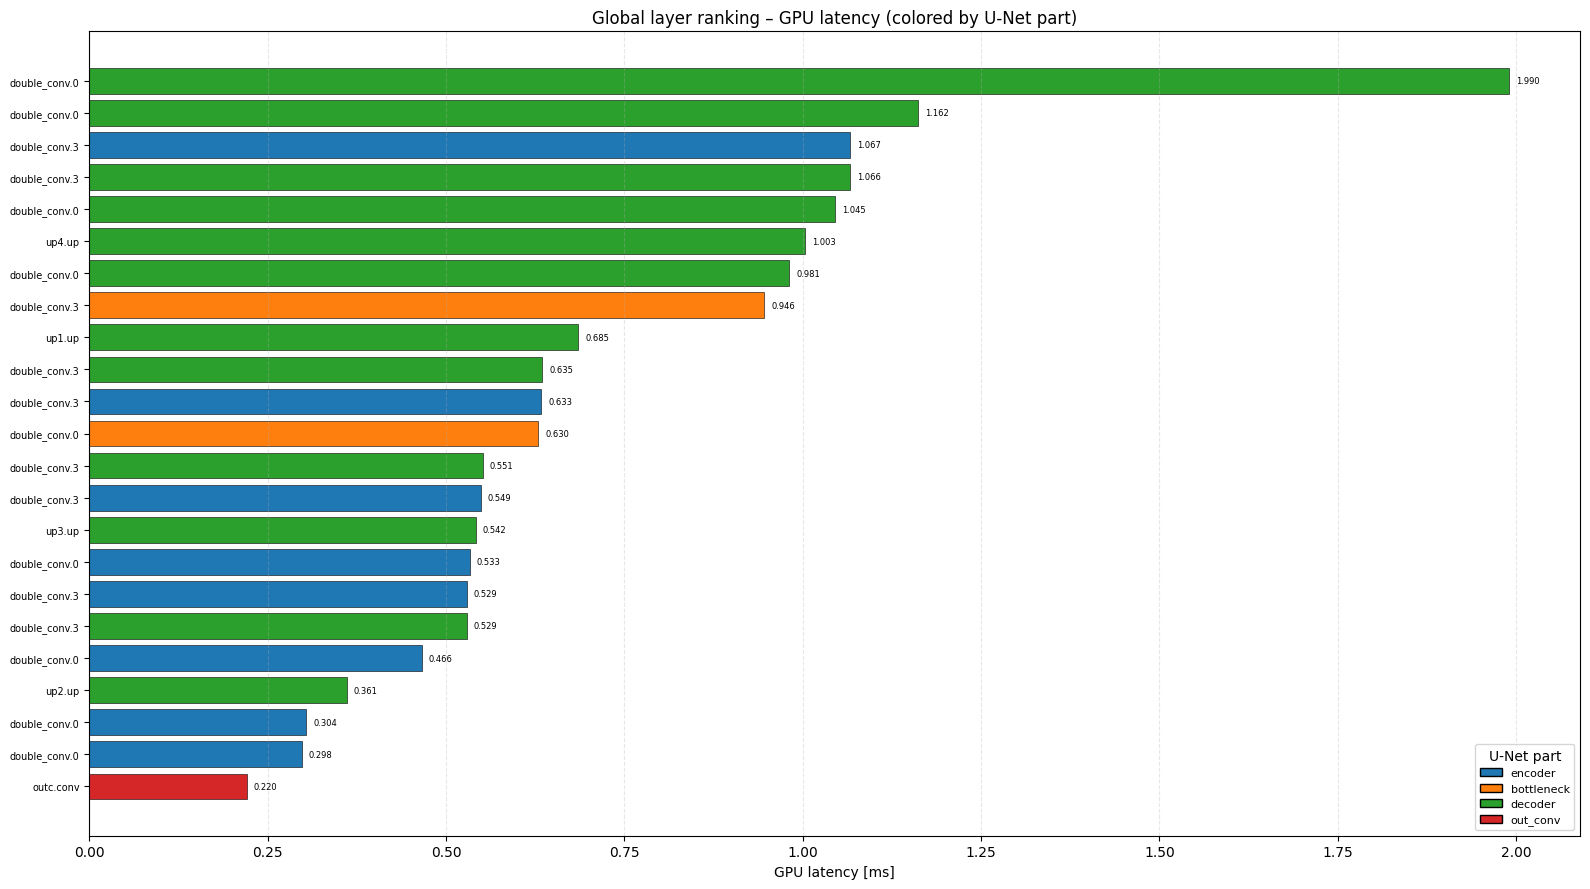

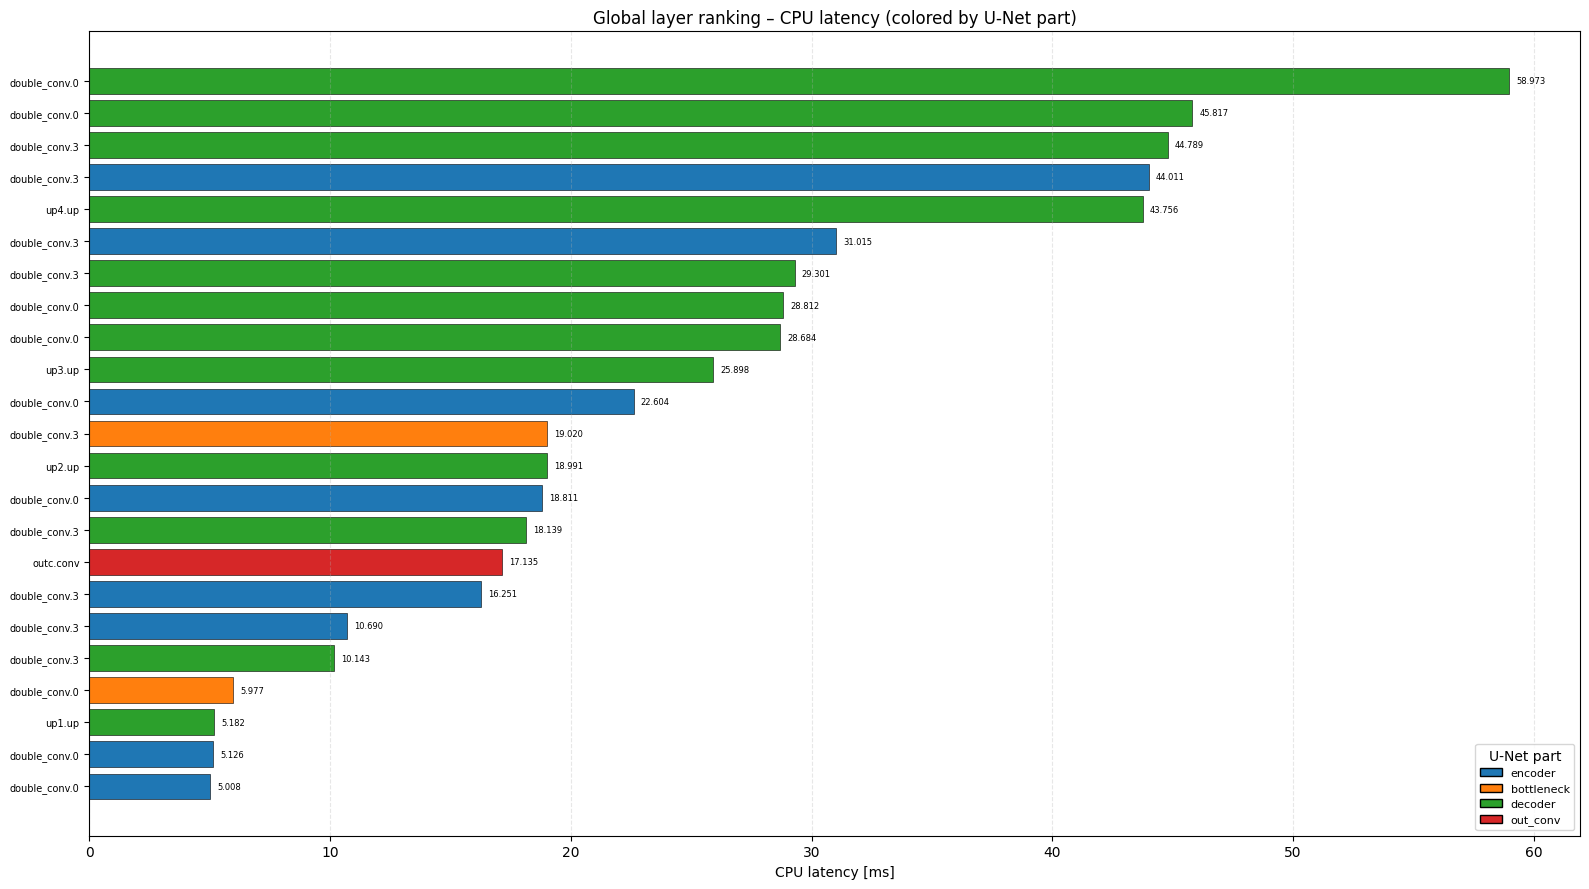

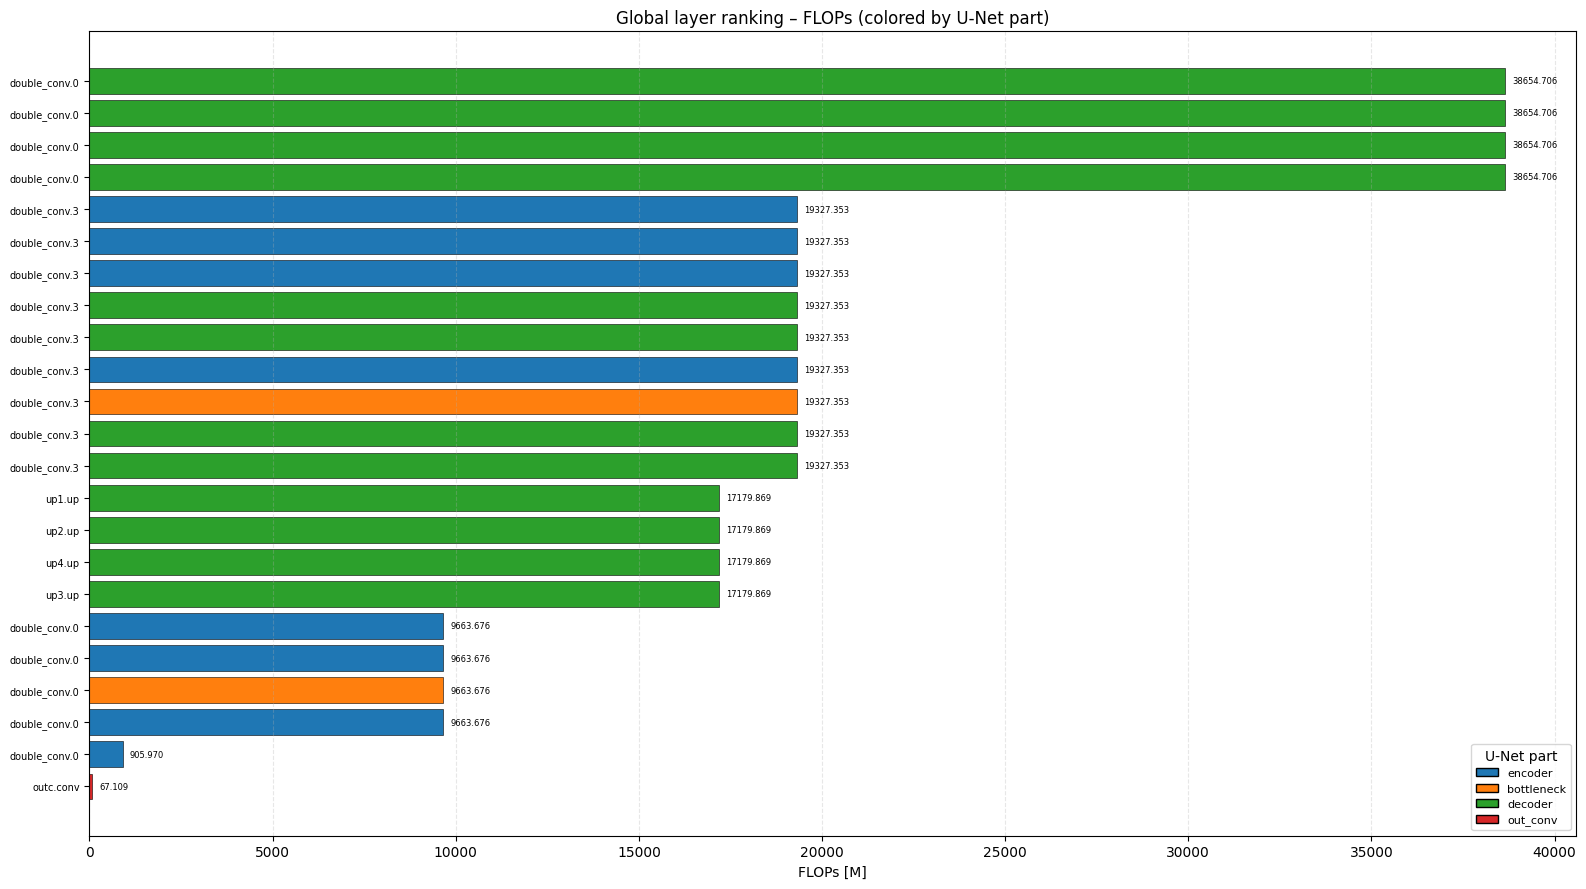

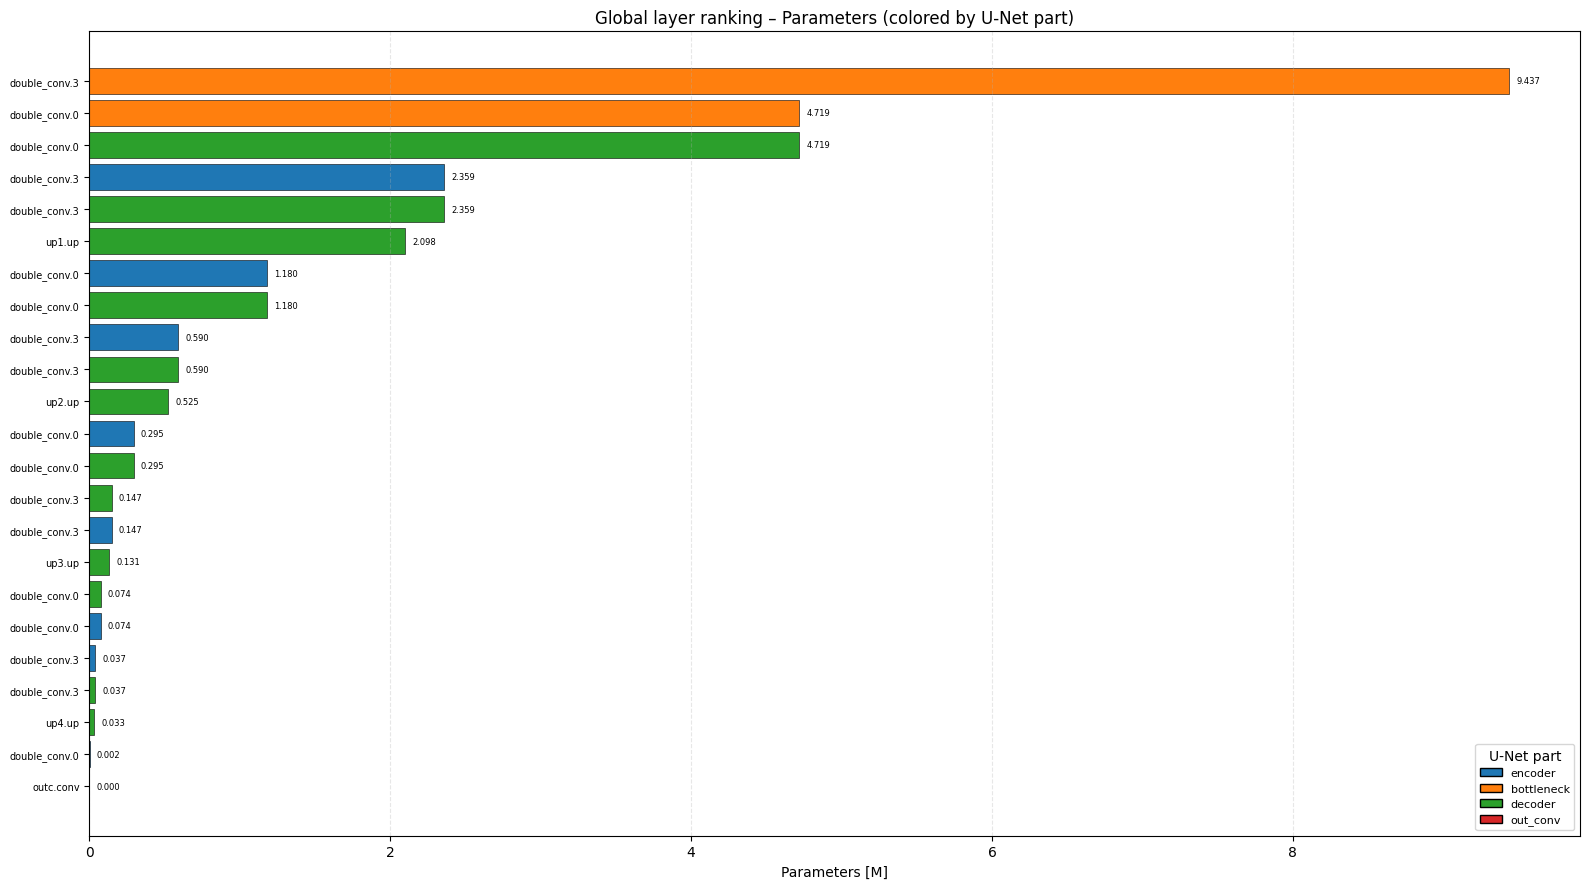

In [10]:
PART_COLORS = {
    'encoder'    : 'tab:blue',
    'bottleneck' : 'tab:orange',
    'decoder'    : 'tab:green',
    'out_conv'   : 'tab:red',
    'unknown'    : 'gray',
}


def plot_global_ranking(df_sorted: pd.DataFrame,
                        value_col: str,
                        ylabel: str,
                        title: str,
                        part_colors: dict,
                        top_n: int = None,
                        figsize=(16, 5)):
    """
    Horizontal bar chart, one bar per layer, ordered by value_col (desc).
    Bars are colored by U-Net part.  Legend shows part membership.
    top_n: if set, show only the top-N most expensive layers.
    """
    df = df_sorted.copy()
    if top_n is not None:
        df = df.head(top_n)

    # Short labels: last two path components
    labels = [
        '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
        for n in df['layer_name']
    ]
    colors = [part_colors.get(p, 'gray') for p in df['part']]
    values = df[value_col].values

    fig, ax = plt.subplots(figsize=figsize)
    y_pos = np.arange(len(labels))
    bars = ax.barh(y_pos, values, color=colors, edgecolor='black', linewidth=0.4)

    for bar, v in zip(bars, values):
        ax.text(bar.get_width() + values.max() * 0.005, bar.get_y() + bar.get_height() / 2,
                f'{v:.3f}', va='center', fontsize=6)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=7)
    ax.invert_yaxis()  # rank-1 on top
    ax.set_xlabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='x', linestyle='--', alpha=0.3)

    # Legend
    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=c, edgecolor='black', label=p)
        for p, c in part_colors.items()
        if p in df['part'].values
    ]
    ax.legend(handles=legend_handles, loc='lower right', fontsize=8, title='U-Net part')

    plt.tight_layout()
    plt.show()


# ── GPU Latency ranking ───────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_gpu, 'time_gpu_ms', 'GPU latency [ms]',
    'Global layer ranking – GPU latency (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── CPU Latency ranking ───────────────────────────────────────────────────
df_ranked_cpu = df_layers.sort_values('time_cpu_ms', ascending=False).reset_index(drop=True)
plot_global_ranking(
    df_ranked_cpu, 'time_cpu_ms', 'CPU latency [ms]',
    'Global layer ranking – CPU latency (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── FLOPs ranking ────────────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_flops, 'flops_M', 'FLOPs [M]',
    'Global layer ranking – FLOPs (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── Parameters ranking ───────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_params, 'params_M', 'Parameters [M]',
    'Global layer ranking – Parameters (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

### 2.7  Within-part ranking (secondary reference)

Same layers, but now the ranking is **within each part** so you can see
which layers are cheapest/most expensive *relative to their neighbours*.
The global rank is still shown for cross-part comparison.

In [11]:
# ── Within-part rank columns ────────────────────────────────────────────
for metric in ('params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms'):
    df_layers[f'part_rank_{metric}'] = (
        df_layers.groupby('part')[metric]
        .rank(ascending=False, method='min')
        .astype(int)
    )

# ── Print within-part table for each part ──────────────────────────────
detail_cols = [
    'part_rank_time_gpu_ms', 'rank_time_gpu_ms',
    'layer_name', 'type', 'in_ch', 'out_ch', 'kernel',
    'params_M', 'flops_M', 'time_gpu_ms'
]

for part in ('encoder', 'bottleneck', 'decoder', 'out_conv'):
    subset = (
        df_layers[df_layers['part'] == part]
        .sort_values('time_gpu_ms', ascending=False)
        .reset_index(drop=True)
    )
    if subset.empty:
        continue
    print(f'\n=== Within-part ranking: {part.upper()} ===')
    display(subset[detail_cols])


=== Within-part ranking: ENCODER ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,3,inc.double_conv.3,Conv2d,64,64,"(3, 3)",0.036864,19327.352832,1.066672
1,2,11,down1.maxpool_conv.1.double_conv.3,Conv2d,128,128,"(3, 3)",0.147456,19327.352832,0.633014
2,3,14,down3.maxpool_conv.1.double_conv.3,Conv2d,512,512,"(3, 3)",2.359296,19327.352832,0.548666
3,4,16,down1.maxpool_conv.1.double_conv.0,Conv2d,64,128,"(3, 3)",0.073728,9663.676416,0.533292
4,5,17,down2.maxpool_conv.1.double_conv.3,Conv2d,256,256,"(3, 3)",0.589824,19327.352832,0.528880
5,6,19,inc.double_conv.0,Conv2d,3,64,"(3, 3)",0.001728,905.969664,0.465783
6,7,21,down2.maxpool_conv.1.double_conv.0,Conv2d,128,256,"(3, 3)",0.294912,9663.676416,0.303804
7,8,22,down3.maxpool_conv.1.double_conv.0,Conv2d,256,512,"(3, 3)",1.179648,9663.676416,0.297537



=== Within-part ranking: BOTTLENECK ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,8,down4.maxpool_conv.1.double_conv.3,Conv2d,1024,1024,"(3, 3)",9.437184,19327.352832,0.945977
1,2,12,down4.maxpool_conv.1.double_conv.0,Conv2d,512,1024,"(3, 3)",4.718592,9663.676416,0.629538



=== Within-part ranking: DECODER ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,1,up4.conv.double_conv.0,Conv2d,128,64,"(3, 3)",0.073728,38654.705664,1.990308
1,2,2,up3.conv.double_conv.0,Conv2d,256,128,"(3, 3)",0.294912,38654.705664,1.162344
2,3,4,up4.conv.double_conv.3,Conv2d,64,64,"(3, 3)",0.036864,19327.352832,1.065625
3,4,5,up1.conv.double_conv.0,Conv2d,1024,512,"(3, 3)",4.718592,38654.705664,1.045174
4,5,6,up4.up,ConvTranspose2d,128,64,"(2, 2)",0.032832,17179.869184,1.003349
5,6,7,up2.conv.double_conv.0,Conv2d,512,256,"(3, 3)",1.179648,38654.705664,0.981162
6,7,9,up1.up,ConvTranspose2d,1024,512,"(2, 2)",2.097664,17179.869184,0.685136
7,8,10,up3.conv.double_conv.3,Conv2d,128,128,"(3, 3)",0.147456,19327.352832,0.634905
8,9,13,up1.conv.double_conv.3,Conv2d,512,512,"(3, 3)",2.359296,19327.352832,0.551067
9,10,15,up3.up,ConvTranspose2d,256,128,"(2, 2)",0.131200,17179.869184,0.541583



=== Within-part ranking: OUT_CONV ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,23,outc.conv,Conv2d,64,2,"(1, 1)",0.00013,67.108864,0.220195


### 2.8  Within-part ranking – visual (GPU latency)

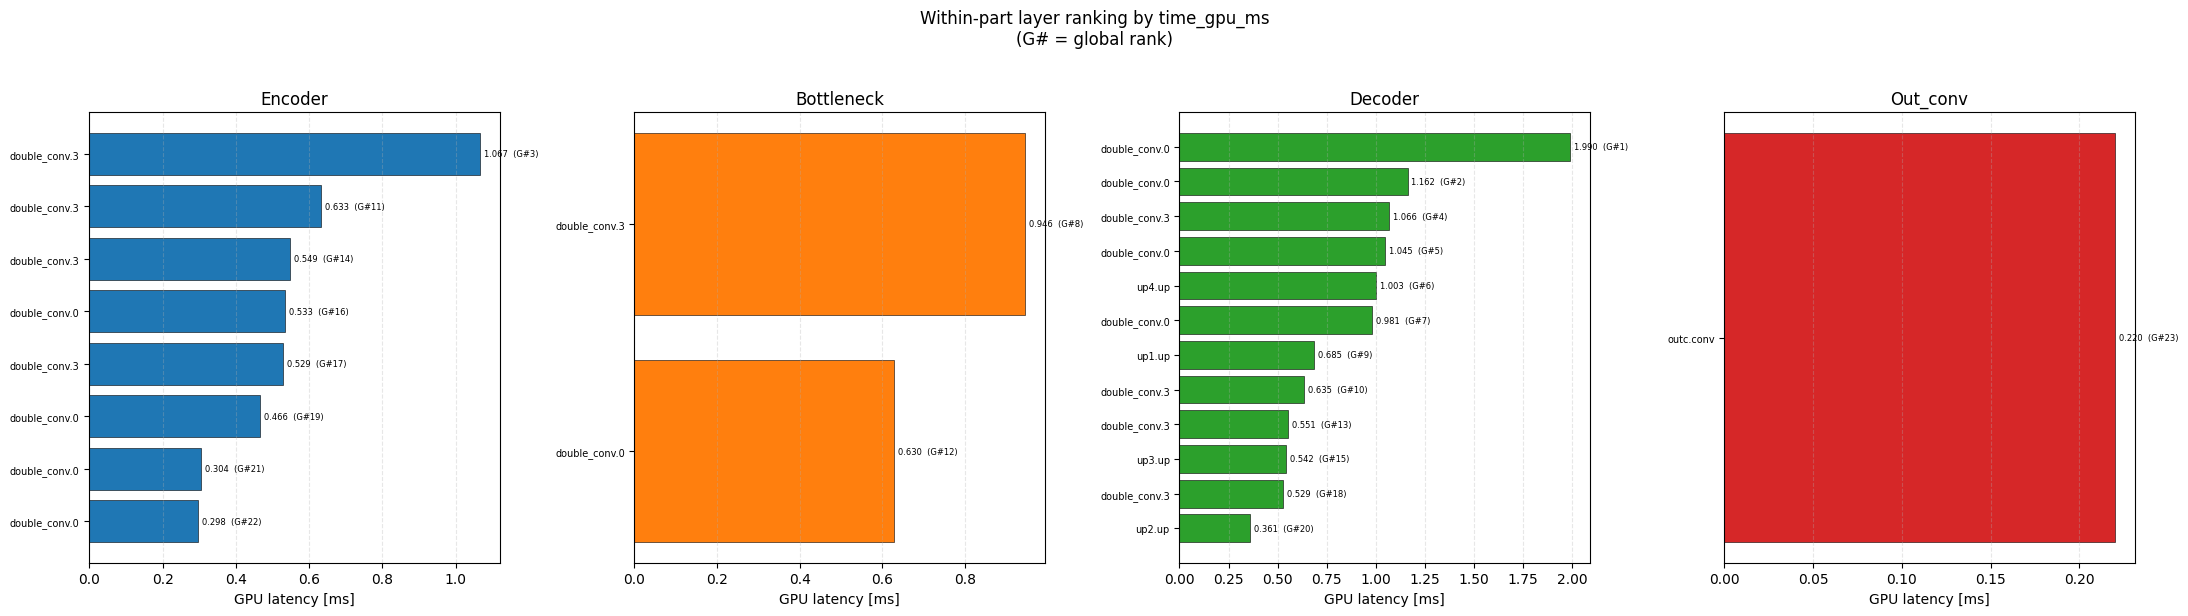

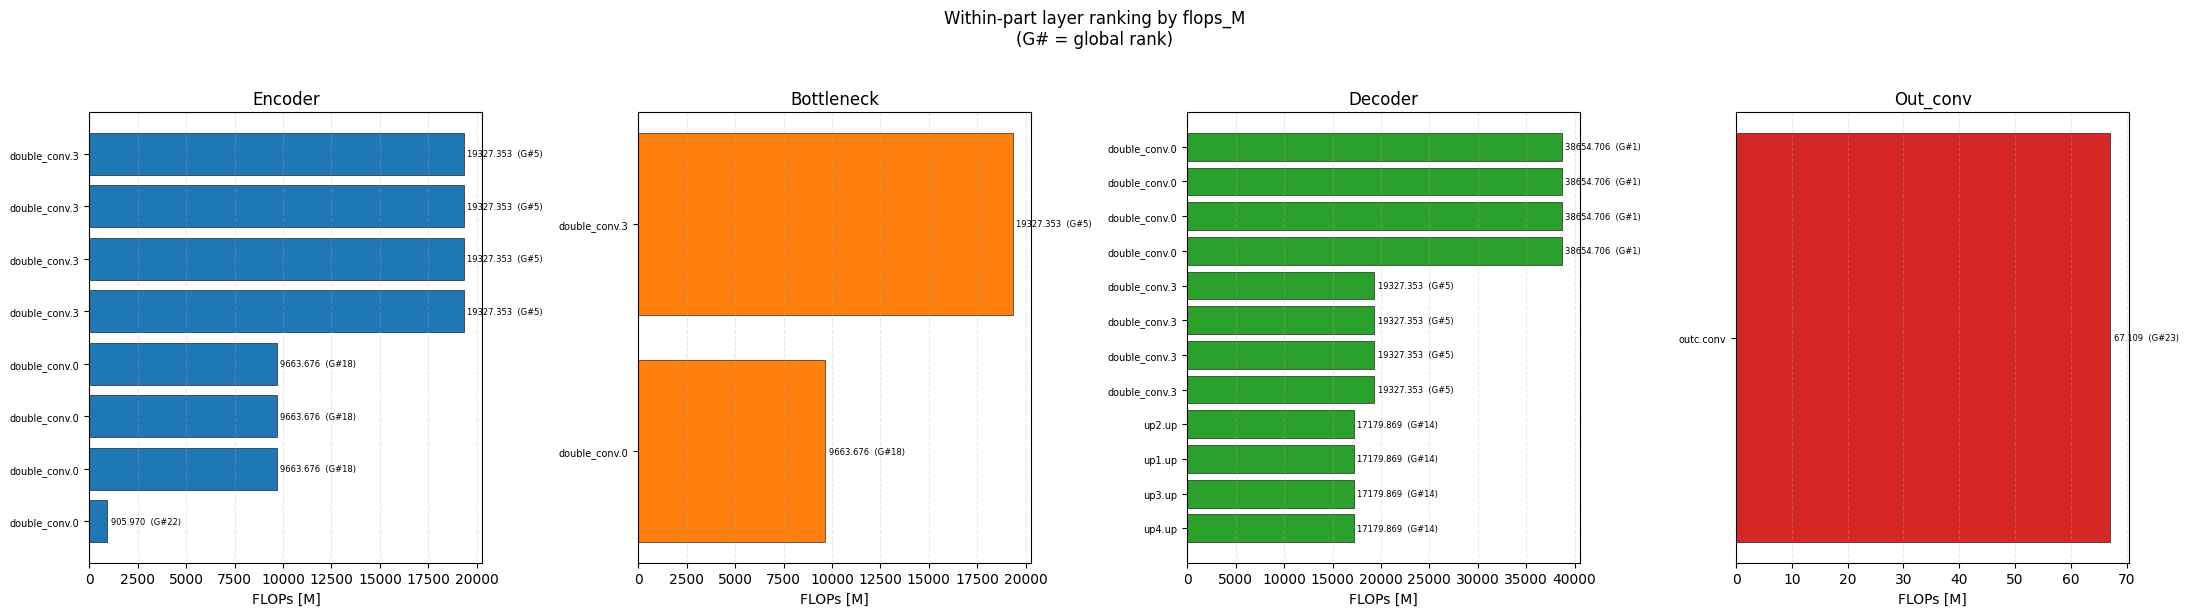

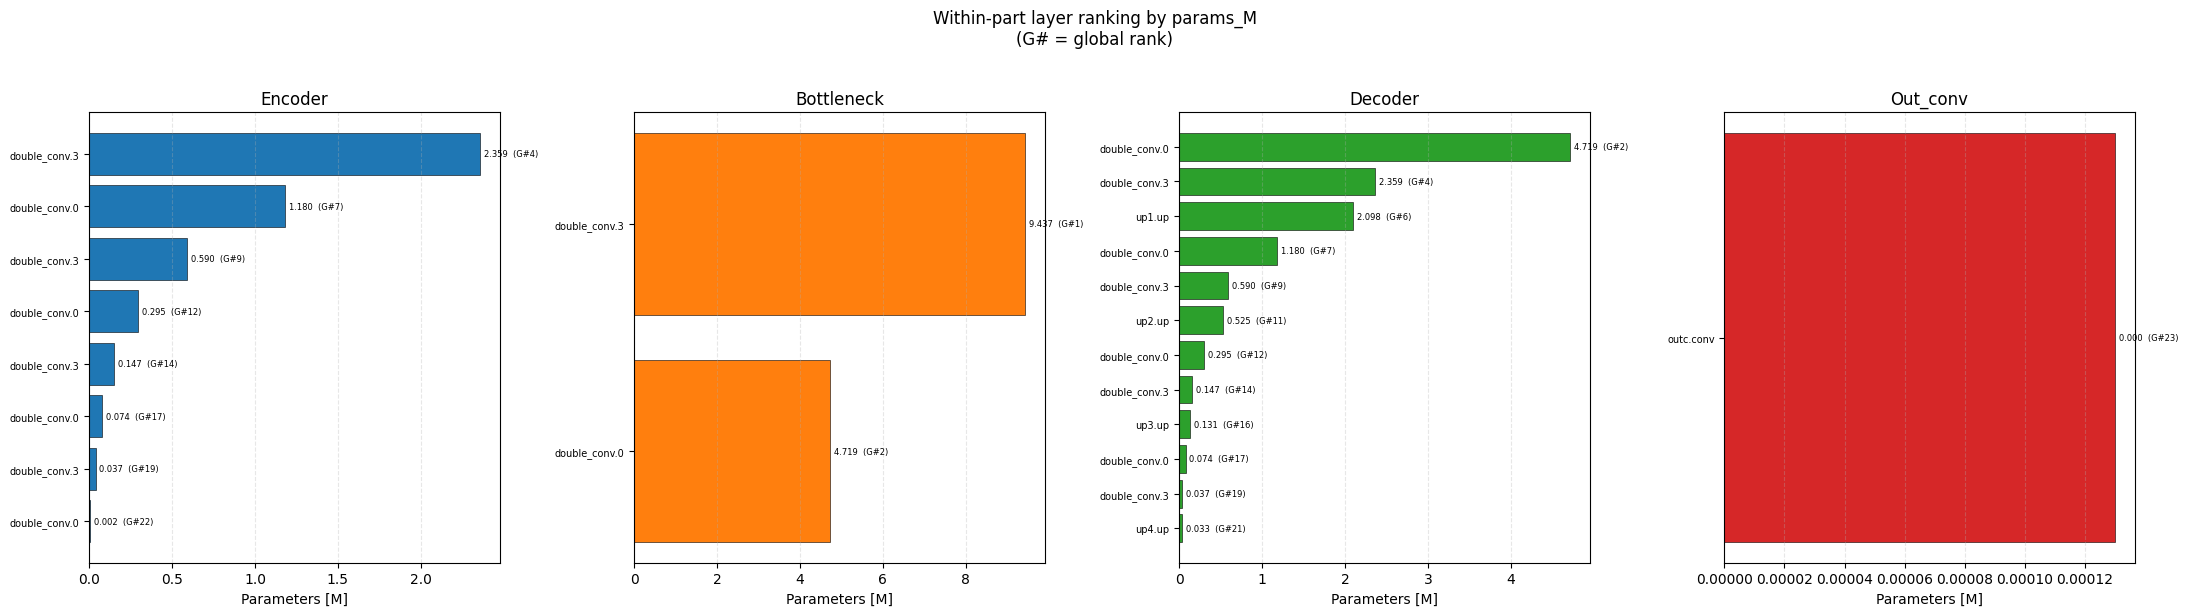

In [12]:
def plot_within_part_ranking(df_layers: pd.DataFrame,
                             value_col: str,
                             ylabel: str,
                             part_colors: dict,
                             figsize=(18, 5)):
    """
    One subplot per U-Net part.  Within each subplot layers are ranked
    descending by value_col.  Global rank shown in bar label.
    """
    parts = ['encoder', 'bottleneck', 'decoder', 'out_conv']
    parts = [p for p in parts if p in df_layers['part'].values]
    n = len(parts)

    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=False)
    if n == 1:
        axes = [axes]

    global_rank_col = f'rank_{value_col}'

    for ax, part in zip(axes, parts):
        sub = (
            df_layers[df_layers['part'] == part]
            .sort_values(value_col, ascending=False)
            .reset_index(drop=True)
        )
        labels = [
            '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
            for n in sub['layer_name']
        ]
        values = sub[value_col].values
        g_ranks = sub[global_rank_col].values if global_rank_col in sub else None
        color   = part_colors.get(part, 'gray')

        y_pos = np.arange(len(labels))
        bars = ax.barh(y_pos, values, color=color, edgecolor='black', linewidth=0.4)

        for i, (bar, v) in enumerate(zip(bars, values)):
            label_str = f'{v:.3f}'
            if g_ranks is not None:
                label_str += f'  (G#{g_ranks[i]})'
            ax.text(bar.get_width() + values.max() * 0.01,
                    bar.get_y() + bar.get_height() / 2,
                    label_str, va='center', fontsize=6)

        ax.set_yticks(y_pos)
        ax.set_yticklabels(labels, fontsize=7)
        ax.invert_yaxis()
        ax.set_xlabel(ylabel)
        ax.set_title(part.capitalize())
        ax.grid(axis='x', linestyle='--', alpha=0.3)

    fig.suptitle(f'Within-part layer ranking by {value_col}\n(G# = global rank)', y=1.02)
    plt.tight_layout()
    plt.show()


plot_within_part_ranking(
    df_layers, 'time_gpu_ms', 'GPU latency [ms]', PART_COLORS, figsize=(22, 6)
)
plot_within_part_ranking(
    df_layers, 'flops_M', 'FLOPs [M]', PART_COLORS, figsize=(22, 6)
)
plot_within_part_ranking(
    df_layers, 'params_M', 'Parameters [M]', PART_COLORS, figsize=(22, 6)
)

### 2.9  Cumulative cost – top-K layers cover X% of total cost

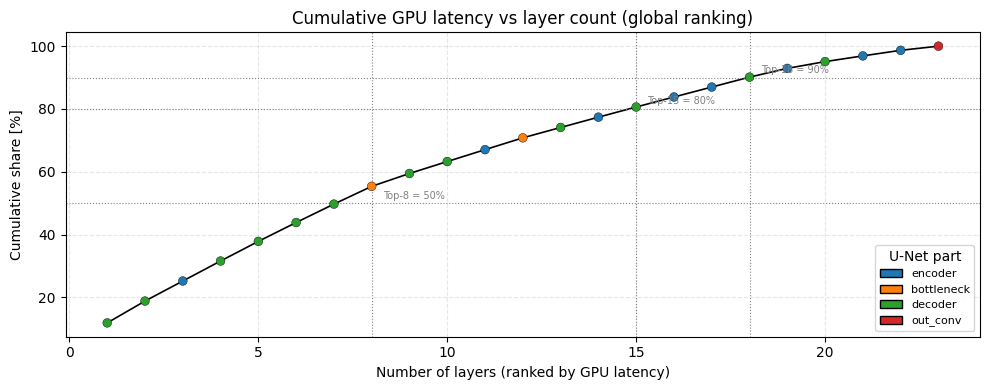

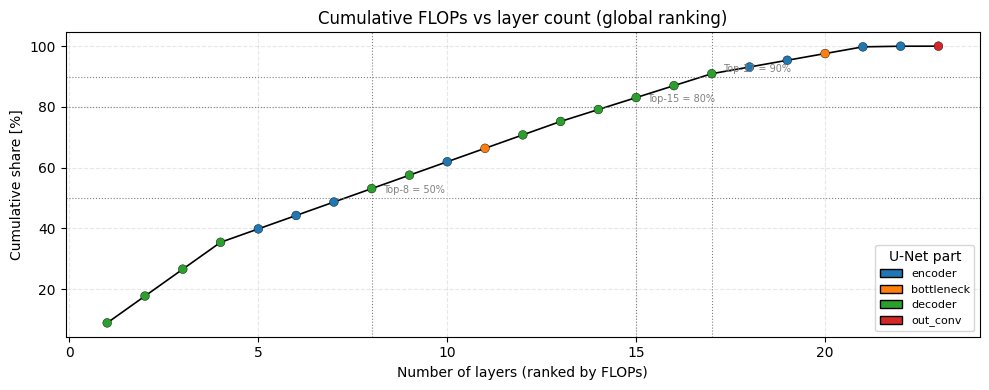

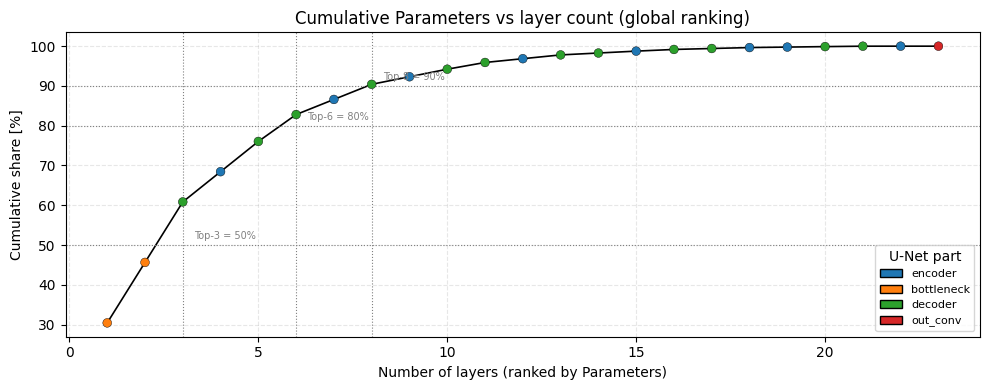

In [13]:
def plot_cumulative_cost(df_ranked: pd.DataFrame,
                         value_col: str,
                         xlabel: str,
                         part_colors: dict,
                         title: str,
                         figsize=(10, 4)):
    """
    Cumulative % of total cost as layers are added (most expensive first).
    Dots are colored by part.
    """
    vals   = df_ranked[value_col].values
    parts  = df_ranked['part'].values
    total  = vals.sum()
    cumsum = np.cumsum(vals) / (total + 1e-12) * 100.0
    colors = [part_colors.get(p, 'gray') for p in parts]

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(np.arange(1, len(cumsum) + 1), cumsum, color='black', linewidth=1.2, zorder=2)
    ax.scatter(np.arange(1, len(cumsum) + 1), cumsum,
               c=colors, s=40, zorder=3, edgecolors='black', linewidths=0.3)

    for thr in (50, 80, 90):
        idx = np.searchsorted(cumsum, thr)
        if idx < len(cumsum):
            ax.axhline(thr, color='gray', linestyle=':', linewidth=0.8)
            ax.axvline(idx + 1, color='gray', linestyle=':', linewidth=0.8)
            ax.text(idx + 1.3, thr + 1.5,
                    f'Top-{idx+1} = {thr}%', fontsize=7, color='gray')

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Cumulative share [%]')
    ax.set_title(title)
    ax.grid(linestyle='--', alpha=0.3)

    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=c, edgecolor='black', label=p)
        for p, c in part_colors.items()
        if p in df_ranked['part'].values
    ]
    ax.legend(handles=legend_handles, fontsize=8, title='U-Net part')

    plt.tight_layout()
    plt.show()


plot_cumulative_cost(
    df_ranked_gpu, 'time_gpu_ms', 'Number of layers (ranked by GPU latency)',
    PART_COLORS, 'Cumulative GPU latency vs layer count (global ranking)', figsize=(10, 4)
)
plot_cumulative_cost(
    df_ranked_flops, 'flops_M', 'Number of layers (ranked by FLOPs)',
    PART_COLORS, 'Cumulative FLOPs vs layer count (global ranking)', figsize=(10, 4)
)
plot_cumulative_cost(
    df_ranked_params, 'params_M', 'Number of layers (ranked by Parameters)',
    PART_COLORS, 'Cumulative Parameters vs layer count (global ranking)', figsize=(10, 4)
)

### 2.10  Summary: part-level aggregate from individual layer profiling

This re-creates the macro-section view but derived bottom-up from the per-layer
measurements, so both levels are consistent.

In [14]:
df_part_summary = (
    df_layers
    .groupby('part', sort=False)
    .agg(
        n_layers       = ('layer_name', 'count'),
        params_M_total = ('params_M',    'sum'),
        flops_M_total  = ('flops_M',     'sum'),
        time_gpu_ms    = ('time_gpu_ms', 'sum'),
        time_cpu_ms    = ('time_cpu_ms', 'sum'),
    )
    .reset_index()
)

# Share columns
for metric in ('params_M_total', 'flops_M_total', 'time_gpu_ms', 'time_cpu_ms'):
    total = df_part_summary[metric].sum()
    df_part_summary[f'{metric}_share%'] = (
        100.0 * df_part_summary[metric] / (total + 1e-12)
    ).round(1)

# Enforce logical order
order = ['encoder', 'bottleneck', 'decoder', 'out_conv']
df_part_summary['_ord'] = df_part_summary['part'].map(
    {p: i for i, p in enumerate(order)}
).fillna(99)
df_part_summary = df_part_summary.sort_values('_ord').drop(columns='_ord').reset_index(drop=True)

print('Part-level summary (aggregated from individual layer measurements):')
df_part_summary

Part-level summary (aggregated from individual layer measurements):


,part,n_layers,params_M_total,flops_M_total,time_gpu_ms,time_cpu_ms,params_M_total_share%,flops_M_total_share%,time_gpu_ms_share%,time_cpu_ms_share%
0,encoder,8,4.683456,107206.410240,4.377646,153.514070,15.1,24.5,26.2,27.7
1,bottleneck,2,14.155776,28991.029248,1.575514,24.997010,45.6,6.6,9.4,4.5
2,decoder,12,12.186560,300647.710720,10.550175,358.485488,39.3,68.8,63.1,64.7
3,out_conv,1,0.000130,67.108864,0.220195,17.134520,0.0,0.0,1.3,3.1


### 2.11  Pruning budget guidance table

Ranks layers globally by GPU latency and recommends a pruning budget
proportional to their cost share, while showing which U-Net part each
layer belongs to as a structural reference.

In [15]:
def build_pruning_budget_table(df_layers: pd.DataFrame,
                               rank_by: str = 'time_gpu_ms') -> pd.DataFrame:
    """
    Returns a DataFrame with suggested pruning budget per layer.

    Budget logic:
      - Layers are sorted globally by `rank_by` (descending, most costly first).
      - suggested_sparsity = cost_share * 0.8  (clipped to [0.1, 0.7])
        meaning the most costly layers get the highest sparsity target.

    This is only a starting heuristic; accuracy-aware refinement should follow.
    """
    df = df_layers.sort_values(rank_by, ascending=False).copy().reset_index(drop=True)
    total = df[rank_by].sum()
    df['cost_share%'] = 100.0 * df[rank_by] / (total + 1e-12)

    # Sparsity heuristic: higher cost -> higher sparsity target
    max_share = df['cost_share%'].max()
    df['suggested_sparsity'] = (
        (df['cost_share%'] / max_share) * 0.7
    ).clip(0.1, 0.7).round(2)

    cols = [
        f'rank_{rank_by}', 'part', 'layer_name', 'type',
        'in_ch', 'out_ch', 'params_M', 'flops_M', rank_by,
        'cost_share%', 'suggested_sparsity',
        'part_rank_time_gpu_ms',
    ]
    cols = [c for c in cols if c in df.columns]
    return df[cols]


df_budget = build_pruning_budget_table(df_layers, rank_by='flops_M')
print('Pruning budget guidance table (ranked by flops_M):')
df_budget

Pruning budget guidance table (ranked by flops_M):


,rank_flops_M,part,layer_name,type,in_ch,out_ch,params_M,flops_M,flops_M,cost_share%,suggested_sparsity,part_rank_time_gpu_ms
0,1,decoder,up4.conv.double_conv.0,Conv2d,128,64,0.073728,38654.705664,38654.705664,8.847247,0.70,1
1,1,decoder,up1.conv.double_conv.0,Conv2d,1024,512,4.718592,38654.705664,38654.705664,8.847247,0.70,4
2,1,decoder,up2.conv.double_conv.0,Conv2d,512,256,1.179648,38654.705664,38654.705664,8.847247,0.70,6
3,1,decoder,up3.conv.double_conv.0,Conv2d,256,128,0.294912,38654.705664,38654.705664,8.847247,0.70,2
4,5,encoder,inc.double_conv.3,Conv2d,64,64,0.036864,19327.352832,19327.352832,4.423623,0.35,1
5,5,encoder,down2.maxpool_conv.1.double_conv.3,Conv2d,256,256,0.589824,19327.352832,19327.352832,4.423623,0.35,5
6,5,encoder,down1.maxpool_conv.1.double_conv.3,Conv2d,128,128,0.147456,19327.352832,19327.352832,4.423623,0.35,2
7,5,decoder,up4.conv.double_conv.3,Conv2d,64,64,0.036864,19327.352832,19327.352832,4.423623,0.35,3
8,5,decoder,up2.conv.double_conv.3,Conv2d,256,256,0.589824,19327.352832,19327.352832,4.423623,0.35,11
9,5,encoder,down3.maxpool_conv.1.double_conv.3,Conv2d,512,512,2.359296,19327.352832,19327.352832,4.423623,0.35,3


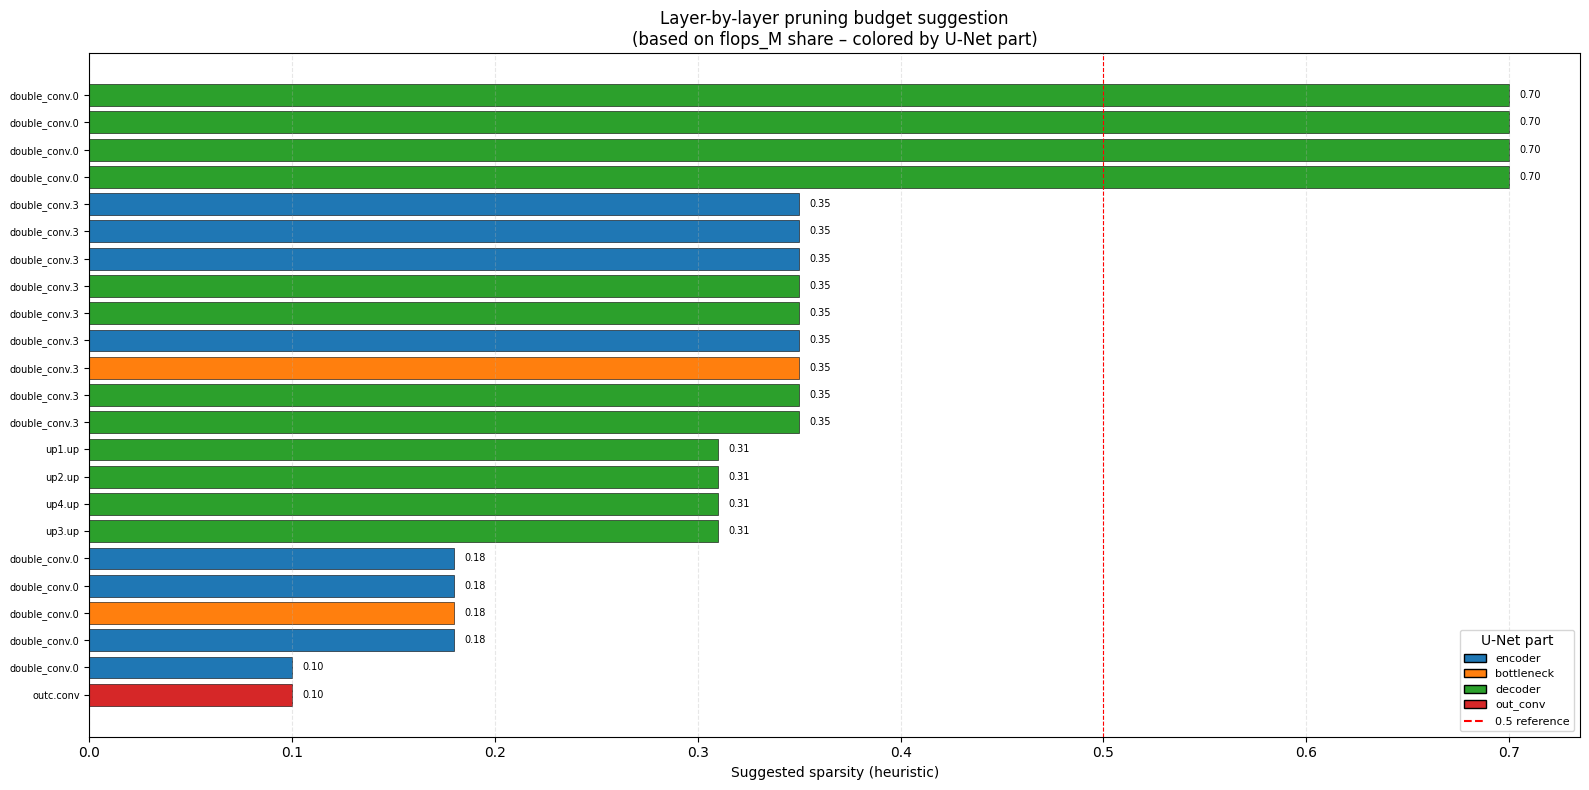

In [16]:
# ── Visualise suggested sparsity ──────────────────────────────────────────
labels = [
    '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
    for n in df_budget['layer_name']
]
colors  = [PART_COLORS.get(p, 'gray') for p in df_budget['part']]
spars   = df_budget['suggested_sparsity'].values

fig, ax = plt.subplots(figsize=(16, 8))
y_pos   = np.arange(len(labels))
bars    = ax.barh(y_pos, spars, color=colors, edgecolor='black', linewidth=0.4)

for bar, v in zip(bars, spars):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{v:.2f}', va='center', fontsize=7)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel('Suggested sparsity (heuristic)')
ax.set_title('Layer-by-layer pruning budget suggestion\n'
             '(based on flops_M share – colored by U-Net part)')
ax.axvline(0.5, color='red', linestyle='--', linewidth=0.8, label='0.5 reference')
ax.grid(axis='x', linestyle='--', alpha=0.3)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=c, edgecolor='black', label=p)
    for p, c in PART_COLORS.items()
    if p in df_budget['part'].values
]
legend_handles.append(
    plt.Line2D([0], [0], color='red', linestyle='--', label='0.5 reference')
)
ax.legend(handles=legend_handles, loc='lower right', fontsize=8, title='U-Net part')

plt.tight_layout()
plt.show()

### 2.12  Export profiling results

In [17]:
out_path = Path('unet_layer_profiling_results.csv')
df_layers.to_csv(out_path, index=False)
print(f'Saved to {out_path.resolve()}')

budget_path = Path('unet_pruning_budget.csv')
df_budget.to_csv(budget_path, index=False)
print(f'Saved to {budget_path.resolve()}')

Saved to /home/jovyan/pruning-u-net-datavol-1/Pytorch-UNet/unet_layer_profiling_results.csv
Saved to /home/jovyan/pruning-u-net-datavol-1/Pytorch-UNet/unet_pruning_budget.csv
